In [ ]:
# Prepare the data
# Read WIDER FACE annotation file so that each image has a list of face/bounding boxes(detecition)
# Download DARK FACE dataset for testing at the end

In [ ]:
# Getting the WIDER FACE data
!pip install gdown
import torchvision.datasets as datasets # Importing the WIDER FACE dataset into Colab memory using PyTorch
wider_face_ds = datasets.WIDERFace(root='/content/data', split='train', download=True)

In [ ]:
# Reading the WIDER FACE annotations
# Parse the existing text file directly
txt_path = '/content/data/widerface/wider_face_split/wider_face_train_bbx_gt.txt'

with open(txt_path, 'r') as f:
    lines = [line.strip() for line in f.readlines()]

# Building dictionary {'relative/path/image.jpg': [[x, y, w, h, invalid], ...]}
wider_dict = {}

i = 0
while i < len(lines):
    img_path = lines[i]
    i += 1
    num_boxes = int(lines[i])
    i += 1

    boxes = []
    if num_boxes == 0:
        i += 1  # Skip placeholder line for images with no faces
    else:
        for _ in range(num_boxes):
            parts = list(map(int, lines[i].split()))
            x, y, w, h = parts[:4]
            invalid = parts[7]  # 0 = valid face, 1 = invalid/ignore

            boxes.append([x, y, w, h, invalid])
            i += 1

    wider_dict[img_path] = boxes

# Display first image as a test
first_img = list(wider_dict.items())[0]
print(first_img)

('0--Parade/0_Parade_marchingband_1_849.jpg', [[449, 330, 122, 149, 0]])


In [ ]:
# Downloading DARK FACE data
from datasets import load_dataset
dark_face_ds = load_dataset("hieupth/dark_face") # Load DARK FACE directly into Colab memory

dark_face_part001.zip: reconstructing file:   0%|          |  0.00B / 4.38GB            

dark_face_part001.zip: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/12000 [00:00<?, ? examples/s]

In [ ]:
# Build the DARK ISP (making the image dark)
# Modify the normal photo to make it look like its taken at night (dark, sensor noise, color shifts)
# The dark pictures should be similar to DARK FACE dataset
# Form the training image into a pair, the normal and the darker image along with the same bounding boxes

<PIL.Image.Image image mode=RGB size=1024x732 at 0x7CC53CCA1FD0>


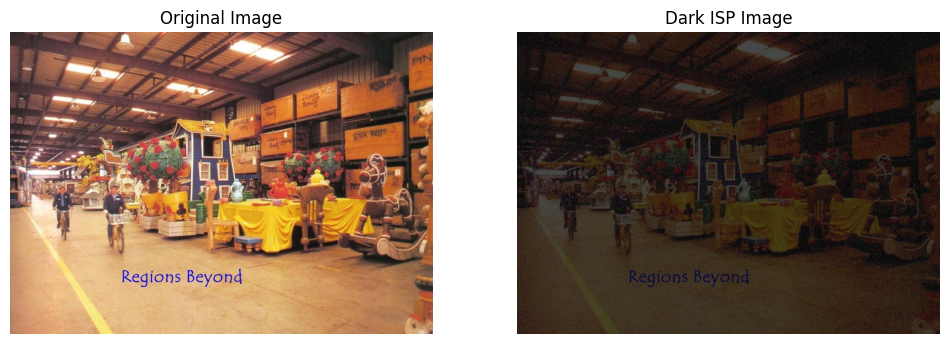

In [ ]:
# Dark ISP -- paired image transformation tool.
# Take a single well-lit image and run it through equations
# (un-gammaing, dimming exposure, adding sensor noise, re-gammaing) to output a dark version.
import torch
import torchvision.transforms.functional as TF
import numpy as np
from PIL import Image

class DarkISP:
  # Synthetically simulating low-light images:
  # Linear inverse ISP -> Low exposure scaling -> Shot/Readout noise -> Forward ISP

  def __init__(self, exposure_range=(0.02, 0.1), shot_noise_range=(0.01, 0.05), read_noise_range=(0.01, 0.03)):
        self.exposure_range = exposure_range
        self.shot_noise_range = shot_noise_range
        self.read_noise_range = read_noise_range

  def __call__(self, img_pil):
        # Normalize PIL Image to Tensor [0.0, 1.0]
        img_tensor = TF.to_tensor(img_pil)

        # Un-gamma mapping (sRGB space -> Linear RAW sensor space)
        linear_img = torch.pow(img_tensor, 2.2)

        # Simulate low exposure time (scale down light intensity)
        alpha = np.random.uniform(*self.exposure_range)
        dark_linear = linear_img * alpha

        # Inject camera sensor noise (Shot noise + Readout noise)
        shot_noise_std = np.random.uniform(*self.shot_noise_range)
        read_noise_std = np.random.uniform(*self.read_noise_range)

        poisson_noise = torch.randn_like(dark_linear) * torch.sqrt(torch.clamp(dark_linear, min=1e-5)) * shot_noise_std
        gaussian_noise = torch.randn_like(dark_linear) * read_noise_std

        noisy_dark_linear = torch.clamp(dark_linear + poisson_noise + gaussian_noise, 0.0, 1.0)

        # Forward ISP (Re-apply gamma correction back to sRGB space)
        dark_srgb = torch.pow(noisy_dark_linear, 1.0 / 2.2)

        return TF.to_pil_image(dark_srgb)


image_path = "/content/data/widerface/WIDER_train/images/0--Parade/0_Parade_Parade_0_1014.jpg"

img_pil = Image.open(image_path).convert("RGB")
dark_isp = DarkISP()
dark_image = dark_isp(img_pil)
print(dark_image)

# Display both images
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_pil)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(dark_image)
plt.title("Dark ISP Image")
plt.axis("off")

plt.show()

{'img_name': '0--Parade/0_Parade_marchingband_1_849.jpg', 'normal_img': <PIL.Image.Image image mode=RGB size=1024x1385 at 0x7CC53C40B250>, 'dark_img': <PIL.Image.Image image mode=RGB size=1024x1385 at 0x7CC53C40BA70>, 'bboxes': tensor([[449., 330., 122., 149.,   0.]])}
0--Parade/0_Parade_marchingband_1_849.jpg
<PIL.Image.Image image mode=RGB size=1024x1385 at 0x7CC53C40BF70>
<PIL.Image.Image image mode=RGB size=1024x1385 at 0x7CC53C40BA70>
tensor([[449., 330., 122., 149.,   0.]])


(np.float64(-0.5), np.float64(1023.5), np.float64(1384.5), np.float64(-0.5))

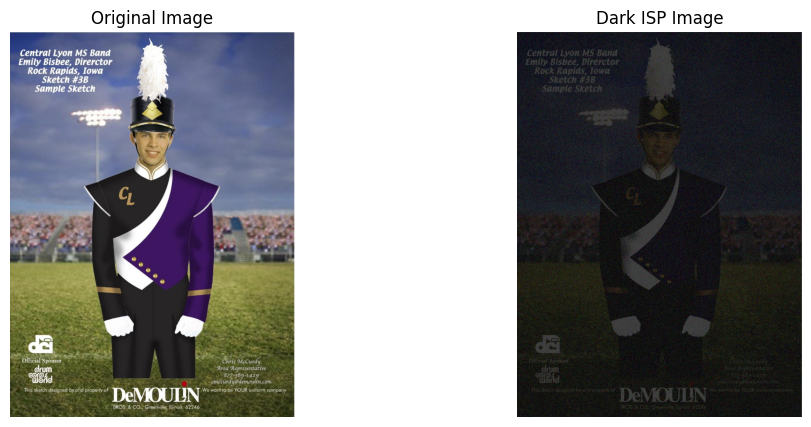

In [ ]:
# Organizer/Fetcher class for dynamically retreiving Dark ISP image pairings during training
import os
import torch
from torch.utils.data import Dataset
from PIL import Image

class PairedWiderFaceDataset(Dataset):
    def __init__(self, img_dir, wider_dict, dark_isp_transform=None, transform=None):
        self.img_dir = img_dir # The root folder path on disk where WIDER FACE images live
        self.wider_dict = wider_dict # wider_dict from before, format: {'0--Parade/0_1.jpg': [[x, y, w, h, invalid], ...]}
        self.img_keys = list(wider_dict.keys()) # Allows us to look up images by index number (e.g., dataset[0], dataset[1])
        self.dark_isp = dark_isp_transform # Create instance of DarkISP class used to darken photo
        self.transform = transform # PyTorch transforms to convert image pixels into numerical matrices for neural network training

    def __len__(self):
        return len(self.img_keys)

    def __getitem__(self, idx):
        # Get the relative file path for this specific index number
        rel_path = self.img_keys[idx]

        # Build the complete file path to locate the image on disk
        full_path = os.path.join(self.img_dir, rel_path)

        # Load original well-lit image
        normal_img = Image.open(full_path).convert('RGB')

        # Generate dark counterpart on the fly
        dark_img = self.dark_isp(normal_img) if self.dark_isp else normal_img

        # Retrieve bounding boxes [x, y, w, h, invalid]; convert to PyTorch Tensor
        bboxes = torch.tensor(self.wider_dict[rel_path], dtype=torch.float32)

        # Apply standard transforms (like converting to Tensor) if provided
        if self.transform:
            normal_img = self.transform(normal_img)
            dark_img = self.transform(dark_img)

        # Returning completed paired dictionary
        return {
            'img_name': rel_path, # Filename string (for tracking/logging)
            'normal_img': normal_img, # Well-lit image tensor (Source domain)
            'dark_img': dark_img, # Low-light image tensor (Target domain pair)
            'bboxes': bboxes # Ground truth face bounding boxes [x, y, w, h, invalid]
        }

paired_dataset = PairedWiderFaceDataset(
    img_dir="/content/data/widerface/WIDER_train/images/",
    wider_dict=wider_dict,
    dark_isp_transform=DarkISP()
)
print(paired_dataset[0])
print(paired_dataset[0]['img_name'])
print(paired_dataset[0]['normal_img'])
print(paired_dataset[0]['dark_img'])
print(paired_dataset[0]['bboxes'])


plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(paired_dataset[0]['normal_img'])
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(paired_dataset[0]['dark_img'])
plt.title("Dark ISP Image")
plt.axis("off")



In [ ]:
from torch.utils.data import DataLoader
import torchvision.transforms as T

# Instantiate the generator
dark_isp = DarkISP()

# Path to WIDER Face training images directory
img_dir = '/content/data/widerface/WIDER_train/images'

# Inialize PyTorch Dataset
train_dataset = PairedWiderFaceDataset(
    img_dir=img_dir,
    wider_dict=wider_dict,
    dark_isp_transform=dark_isp,
    transform=T.ToTensor()
)

# Wrap with DataLoader for batching -- zero RAM overload and better data augmentation (rnadom exposure factors across different epochs)
train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, collate_fn=lambda x: x)

In [ ]:
# Train to split the given image into Reflectance and Illumination
# Once trained, freeze it. It will be used to show what the correct reflectance looks like
# Image pairs are fed to model at the same time

In [ ]:
# Train the plain detector (baseline)
# Train ordinary DSFD (a VGG16 backbone plus detection layers) on daytime image
# Test it on the DARK FACE
# This is to compare how our model will be better and that we beat this baseline model

In [ ]:
# Adding our new processes one at a time
# Reflectance decoder: Attach a small branch to the early VGG16 layers that predicts the reflectance, trained to match the frozen Retinex teacher's output
# Swap and decompose: Swap the reflectance of the day and night versions, rebuild the images, run them again and check that the same reflectance comes out
# Feature alignment: Make the early VGG16 features of the day image and its night twin activate the same channels in the same proportions